# Rilevare l'entanglement di due qubit con una rete neurale

Il problema: **capire se due qubit sono entangled a partire dalle misure fatte su di loro.** È una classificazione
binaria: ogni campione è uno stato di due qubit, le feature sono i risultati medi delle misure, l'etichetta è 1
(entangled) o 0 (separabile).

Il lavoro è in tre parti: (1) costruzione del dataset, (2) modelli lineari, che mostrano che le classi non sono linearmente
separabili, (3) percettrone multistrato, che le separa. Le funzioni di fisica stanno in `qubit.py`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Perceptron, LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import qubit as q

## Parte 1 — Il dataset

Si costruisce il dataset in quattro passi: (1) che cosa sono le feature, (2) da dove viene l'etichetta, (3) come si
generano gli stati, (4) bilanciamento e salvataggio in `dataset.csv`. Le funzioni di fisica stanno in `qubit.py`; qui si
usano e si controllano.

In [2]:
rng = np.random.default_rng(0)   # seed fissato: il dataset e' riproducibile

### 1.1 Le feature: 15 misure

Un qubit si può misurare lungo tre "assi", chiamati $X$, $Y$ e $Z$; ogni misura dà $+1$ o $-1$. Con due qubit, A e B,
si ripete la misura su tante copie dello stesso stato e si fanno le medie. Ne escono **15 numeri fra $-1$ e $1$**:

- 3 medie del solo qubit A (misurato lungo $X$, $Y$ o $Z$);
- 3 medie del solo qubit B;
- 9 **correlazioni**: la media del prodotto dei due esiti, per ogni coppia di assi.

Queste 15 medie sono le feature. Sono tutto ciò che un laboratorio sa dello stato. La funzione `q.feature(rho)` le
calcola a partire dallo stato `rho` (una matrice $4\times4$: è la descrizione matematica completa dello stato).

In [3]:
print(q.NOMI_FEATURE)      # "XI" = X sul qubit A, niente su B;  "XZ" = X su A e Z su B (correlazione)
print(len(q.NOMI_FEATURE), "feature")

['IX', 'IY', 'IZ', 'XI', 'XX', 'XY', 'XZ', 'YI', 'YX', 'YY', 'YZ', 'ZI', 'ZX', 'ZY', 'ZZ']
15 feature


### 1.2 Separabile ed entangled

Uno stato è **separabile** se A e B si possono preparare ciascuno per conto proprio (al più tirando una moneta per
decidere quale coppia preparare): ogni legame fra i due esiti era già deciso prima della misura. Se nessuna ricetta di
questo tipo lo riproduce, lo stato è **entangled**.

Due esempi. Nello **stato di Bell**, il prototipo di stato entangled, ogni qubit da solo dà esiti a caso (medie locali 0),
ma gli esiti di A e B sono legati lungo **tutti e tre gli assi**: correlazione $+1$ (esiti sempre uguali) lungo $X$ e $Z$,
$-1$ (esiti sempre opposti) lungo $Y$.

In [4]:
psi_bell = np.array([1, 0, 0, 1]) / np.sqrt(2)          # stato di Bell
rho_bell = np.outer(psi_bell, psi_bell.conj())

for nome, valore in zip(q.NOMI_FEATURE, q.feature(rho_bell)):
    if abs(valore) > 1e-9:
        print(f"<{nome}> = {valore:+.2f}")

<XX> = +1.00
<YY> = -1.00
<ZZ> = +1.00


La **miscela classica** è l'esempio tipico di stato separabile: metà delle volte la coppia è "0, 0", metà delle volte
"1, 1". Lungo $Z$ gli esiti coincidono sempre, come nello stato di Bell; ma lungo $X$ e $Y$ ogni qubit risponde a caso per
conto proprio e la correlazione sparisce. **L'entanglement è una correlazione che resiste in tutti gli assi; una
correlazione classica vive in un asse solo.** Questa è la differenza che il classificatore deve imparare.

In [5]:
rho_mix = np.diag([0.5, 0, 0, 0.5]).astype(complex)       # miscela classica di 00 e 11

for nome in ["ZZ", "XX", "YY"]:
    i = q.NOMI_FEATURE.index(nome)
    print(f"<{nome}>   Bell: {q.feature(rho_bell)[i]:+.2f}   miscela: {q.feature(rho_mix)[i]:+.2f}")

<ZZ>   Bell: +1.00   miscela: +1.00
<XX>   Bell: +1.00   miscela: +0.00
<YY>   Bell: -1.00   miscela: +0.00


### 1.3 L'etichetta

Per due qubit esiste un test esatto, il **criterio di Peres-Horodecki**: si prende la matrice dello stato, si "specchia"
la parte che riguarda il qubit B (trasposta parziale) e si calcolano gli autovalori. Se ne esce uno **negativo**, lo stato
è entangled; altrimenti è separabile. Nessun caso dubbio: **le etichette sono esatte**.

È quello che fa `q.entangled(rho)`: `eigvalsh(trasposta_parziale(rho)).min() < 0`.

In [6]:
for nome, rho in [("Bell", rho_bell), ("miscela classica", rho_mix)]:
    autov = np.linalg.eigvalsh(q.trasposta_parziale(rho))
    print(f"{nome:18s} autovalori dopo lo specchio = {np.round(autov, 3)}   etichetta = {q.entangled(rho)}")

Bell               autovalori dopo lo specchio = [-0.5  0.5  0.5  0.5]   etichetta = 1
miscela classica   autovalori dopo lo specchio = [0.  0.  0.5 0.5]   etichetta = 0


### 1.4 Come si generano gli stati

Non esistono dataset pubblici di stati già etichettati: si generano, com'è prassi in letteratura. Tre generatori, ognuno
con uno scopo:

- `stato_misto_casuale`: stati **generici**, senza preferenze;
- `stato_puro_con_rumore`: uno stato preso a caso e degradato da una quantità casuale $p$ di rumore, così da popolare la
  **zona di confine** fra le due classi, dove classificare è difficile;
- `stato_separabile_casuale`: stati costruiti **separabili per definizione** (miscele di stati in cui A e B sono
  indipendenti); servono a bilanciare le classi.

Controllo: gli stati separabili per costruzione devono avere sempre etichetta 0.

In [7]:
errori = sum(q.entangled(q.stato_separabile_casuale(rng)) for _ in range(5000))
print(f"separabili per costruzione etichettati entangled: {errori} su 5000")

separabili per costruzione etichettati entangled: 0 su 5000


### 1.5 Generazione, bilanciamento e salvataggio

15 000 stati per generatore, feature ed etichetta per ciascuno, poi **bilanciamento al 50 %** scartando a caso gli
esempi in eccesso della classe più numerosa. Con classi bilanciate l'accuratezza è una metrica leggibile
e il modello non può "barare" rispondendo sempre la classe più frequente.

Il dataset non ha valori mancanti e tutte le feature sono numeriche: non servono imputazione né codifica di variabili
categoriche.

In [8]:
N_PER_FAMIGLIA = 15_000
generatori = {"misto": q.stato_misto_casuale,
              "puro+rumore": q.stato_puro_con_rumore,
              "separabile": q.stato_separabile_casuale}

righe = []
for famiglia, gen in generatori.items():
    for _ in range(N_PER_FAMIGLIA):
        rho = gen(rng)
        righe.append([*q.feature(rho), q.entangled(rho), famiglia])

df = pd.DataFrame(righe, columns=[*q.NOMI_FEATURE, "entangled", "famiglia"])
print(df.groupby("famiglia")["entangled"].mean().round(3))   # frazione di entangled per famiglia

famiglia
misto          0.757
puro+rumore    0.517
separabile     0.000
Name: entangled, dtype: float64


In [9]:
n_min = df["entangled"].value_counts().min()
df_bil = pd.concat([df[df["entangled"] == 0].sample(n_min, random_state=0),
                    df[df["entangled"] == 1].sample(n_min, random_state=0)])
df_bil = df_bil.sample(frac=1, random_state=0).reset_index(drop=True)   # mescola le righe

print(df_bil["entangled"].value_counts())
df_bil.to_csv("dataset.csv", index=False, float_format="%.6f")
df_bil.head()

entangled
1    19124
0    19124
Name: count, dtype: int64


,IX,IY,IZ,XI,XX,XY,XZ,YI,YX,YY,YZ,ZI,ZX,ZY,ZZ,entangled,famiglia
0,-0.098478,0.026793,0.057074,0.031997,-0.373346,0.582977,-0.450526,0.072994,-0.098058,0.465484,0.678407,0.085564,-0.736135,-0.354090,0.145760,1,puro+rumore
1,-0.404915,0.338308,0.003372,-0.140028,0.352717,0.142354,-0.248250,-0.479658,0.475580,-0.399480,0.176082,0.169530,0.008005,0.348278,0.306713,1,puro+rumore
2,-0.105922,-0.134364,0.057855,-0.082145,-0.176940,0.314800,-0.517681,0.155907,-0.581862,-0.272049,0.058184,0.039567,0.181661,-0.486412,-0.351597,1,puro+rumore
3,0.092575,0.230233,0.109790,-0.224911,-0.059751,-0.327634,-0.012801,-0.143903,-0.058492,-0.077652,-0.267862,-0.048358,-0.249142,0.011256,0.025162,0,puro+rumore
4,-0.056689,0.123956,0.268646,0.224495,0.074346,-0.158147,0.767590,-0.198869,0.212622,-0.715881,-0.226249,0.028328,-0.722365,-0.217262,0.033488,1,puro+rumore


### 1.6 Uno sguardo ai dati

Istogramma di ciascuna delle 15 feature, con le due classi sovrapposte. Le distribuzioni differiscono (le correlazioni degli
entangled sono più larghe) ma si sovrappongono molto: **nessuna feature presa da sola separa le classi.** Che cosa serva
per separarle lo diranno i modelli delle parti successive.

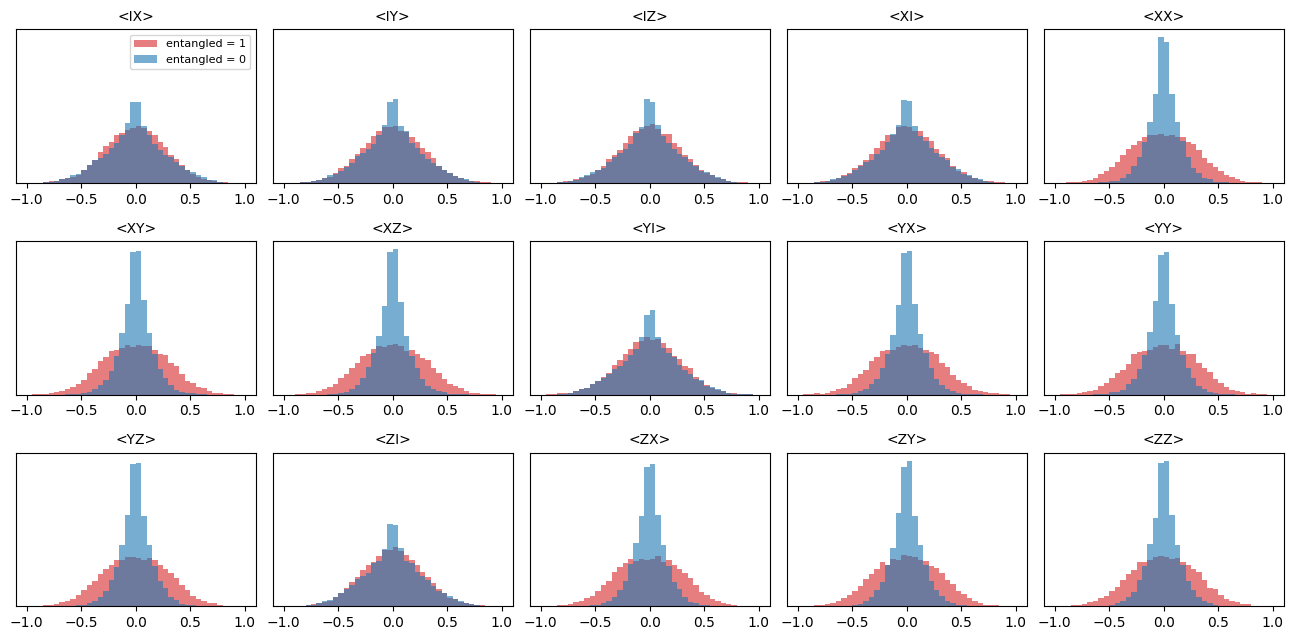

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(13, 6.5), sharey=True)
sub = {cl: df_bil[df_bil["entangled"] == cl] for cl in (0, 1)}

for ax, nome in zip(axes.ravel(), q.NOMI_FEATURE):
    ax.hist(sub[1][nome], bins=40, range=(-1, 1), alpha=0.6, color="tab:red", label="entangled = 1")
    ax.hist(sub[0][nome], bins=40, range=(-1, 1), alpha=0.6, color="tab:blue", label="entangled = 0")
    ax.set_title(f"<{nome}>", fontsize=10)
    ax.set_yticks([])

axes[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### 1.7 Si possono ridurre le feature? Analisi delle componenti principali

Prima di costruire i modelli ci si chiede se 15 feature siano più del necessario. La **PCA** cerca le direzioni dello
spazio delle feature lungo cui i dati variano di più: se poche componenti spiegano quasi tutta la varianza, le altre si
possono scartare senza perdere informazione. Si applica alle feature standardizzate, così nessuna pesa più delle altre
per la sola scala.

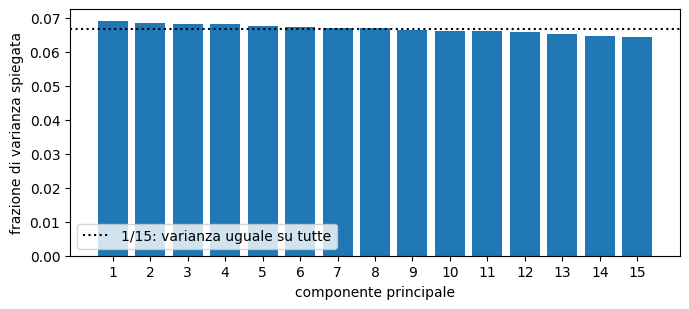

varianza spiegata per componente: [0.069 0.068 0.068 0.068 0.067 0.067 0.067 0.067 0.066 0.066 0.066 0.066
 0.065 0.065 0.064]


In [11]:
X_std = StandardScaler().fit_transform(df_bil[q.NOMI_FEATURE].values)
pca = PCA().fit(X_std)
varianza = pca.explained_variance_ratio_

plt.figure(figsize=(7, 3.2))
plt.bar(range(1, 16), varianza)
plt.axhline(1 / 15, color="k", ls=":", label="1/15: varianza uguale su tutte")
plt.xlabel("componente principale"); plt.ylabel("frazione di varianza spiegata")
plt.xticks(range(1, 16)); plt.legend(); plt.tight_layout(); plt.show()
print("varianza spiegata per componente:", np.round(varianza, 3))

Le 15 componenti spiegano ciascuna circa 1/15 della varianza: **non esiste una direzione privilegiata**, l'informazione
è distribuita uniformemente su tutte le feature. Ha un motivo fisico: gli stati sono generati senza alcun asse di misura
preferito. Scartare componenti significherebbe scartare informazione utile, quindi **la riduzione di dimensionalità non è
possibile** e i modelli lavoreranno su tutte le 15 feature.

## Parte 2 — Modelli lineari

Prima domanda: **le due classi sono linearmente separabili?** Cioè: esiste un iperpiano $z = \mathbf{w}\cdot\mathbf{x} + b = 0$
nello spazio delle 15 feature che lascia gli entangled da una parte e i separabili dall'altra? Per scoprirlo si usano i
modelli lineari più semplici: il perceptron e la regressione logistica.

Percorso: (1) preparazione dei dati, (2) perceptron e logistica sul dataset, (3) lettura del risultato.

In [12]:
df = pd.read_csv("dataset.csv")
X = df[q.NOMI_FEATURE].values          # 15 feature
y = df["entangled"].values             # etichetta 0/1
print(X.shape, y.shape)

(38248, 15) (38248,)


### 2.1 Preparazione dei dati

Si separano **training** e **test** (70/30, stratificato così che le due classi restino
bilanciate in entrambi) e si **standardizzano** le feature con media e deviazione standard calcolate sul solo training. La standardizzazione serve alla discesa del gradiente: feature con scale diverse darebbero
aggiornamenti dei pesi sbilanciati.

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1, stratify=y)

scaler = StandardScaler().fit(X_train)       # media e std stimate sul training
X_train_std = scaler.transform(X_train)
X_test_std = scaler.transform(X_test)

print(f"training: {len(y_train)}   test: {len(y_test)}   frazione entangled nel test: {y_test.mean():.3f}")

training: 26773   test: 11475   frazione entangled nel test: 0.500


### 2.2 Perceptron e regressione logistica

**Perceptron.** Per ogni esempio calcola $z = \mathbf{w}\cdot\mathbf{x} + b$ e predice $\hat y = 1$ se $z > 0$, altrimenti 0. Se
sbaglia corregge i pesi di $\Delta\mathbf{w} = \eta\,(y - \hat y)\,\mathbf{x}$, se indovina non tocca nulla. Converge **solo se
le classi sono linearmente separabili**; altrimenti oscilla, e si ferma quando l'errore non migliora più per 5 epoche
di seguito (`tol`, `n_iter_no_change`).

**Regressione logistica.** Stessa $z$, passata nella sigmoide $\hat y = \sigma(z) \in (0,1)$ e letta come probabilità di
"entangled". I pesi minimizzano la cross-entropy con la discesa del gradiente: converge sempre, ma il confine di decisione
resta l'iperpiano $z = 0$. Poiché la cross-entropy è convessa, il minimo trovato è **il miglior iperpiano possibile**:
è la logistica a rispondere alla domanda; il perceptron è il confronto con il modello più semplice.

**Iperparametri.** Learning rate del perceptron $\eta = 0{,}1$: con feature standardizzate il valore conta poco, scala solo i
pesi; la convergenza dipende dai dati. Regolarizzazione della logistica $C = 1$ (default): con 27 000 esempi e 15 pesi
l'overfitting non è un rischio. `max_iter` è solo un limite di sicurezza, perché entrambi i modelli si fermano prima per il proprio criterio di
arresto: il perceptron quando la perdita non migliora di almeno `tol` per `n_iter_no_change` epoche consecutive (qui succede
dopo poche epoche, perché continua a oscillare senza trovare un iperpiano); la logistica quando il gradiente della
cross-entropy è praticamente nullo, cioè ha raggiunto il minimo.

In [14]:
def matrice_confusione(y_vero, y_pred):
    # classe positiva (entangled = 1) nella prima riga e prima colonna, come nella convenzione usuale
    m = confusion_matrix(y_vero, y_pred, labels=[1, 0])
    return pd.DataFrame(m, index=["reale: entangled", "reale: separabile"],
                           columns=["predetto: entangled", "predetto: separabile"])

ppn = Perceptron(eta0=0.1, max_iter=1000, tol=1e-3, n_iter_no_change=5, random_state=1)
ppn.fit(X_train_std, y_train)

lr = LogisticRegression(C=1.0, max_iter=1000, random_state=1)
lr.fit(X_train_std, y_train)

for nome, modello in [("PERCEPTRON", ppn), ("REGRESSIONE LOGISTICA", lr)]:
    y_pred_train = modello.predict(X_train_std)
    y_pred_test = modello.predict(X_test_std)
    print(f"==== {nome}   (iterazioni eseguite: {int(np.ravel(modello.n_iter_)[0])})")
    print(f"esempi sbagliati nel training: {(y_train != y_pred_train).sum()} su {len(y_train)}")
    print(f"accuratezza training = {accuracy_score(y_train, y_pred_train):.3f}   test = {accuracy_score(y_test, y_pred_test):.3f}")
    print(matrice_confusione(y_test, y_pred_test), "\n")

==== PERCEPTRON   (iterazioni eseguite: 9)
esempi sbagliati nel training: 14563 su 26773
accuratezza training = 0.456   test = 0.461
                   predetto: entangled  predetto: separabile
reale: entangled                  4025                  1713
reale: separabile                 4470                  1267 

==== REGRESSIONE LOGISTICA   (iterazioni eseguite: 2)
esempi sbagliati nel training: 13285 su 26773
accuratezza training = 0.504   test = 0.500
                   predetto: entangled  predetto: separabile
reale: entangled                  2699                  3039
reale: separabile                 2703                  3034 



**Entrambi i modelli sono fermi intorno al 50 %, l'accuratezza di una moneta, già sul training.** Il perceptron si
arresta dopo poche epoche perché l'errore non migliora, e resta con i pesi dell'ultima oscillazione: per questo è
perfino sotto il 50 % e sbilanciato verso una classe (predice "entangled" in tre casi su quattro, qualunque sia la classe vera). La logistica arriva al minimo
della cross-entropy in due iterazioni, ma quel minimo lascia metà degli esempi dalla parte sbagliata: la matrice di
confusione è quasi uniforme. Il fatto che il training non vada
meglio del test esclude l'overfitting: è proprio **il tipo di confine** a essere sbagliato. Le classi **non sono
linearmente separabili**, e l'istogramma dei valori di $z$ nelle due classi lo mostra: le due distribuzioni coincidono.

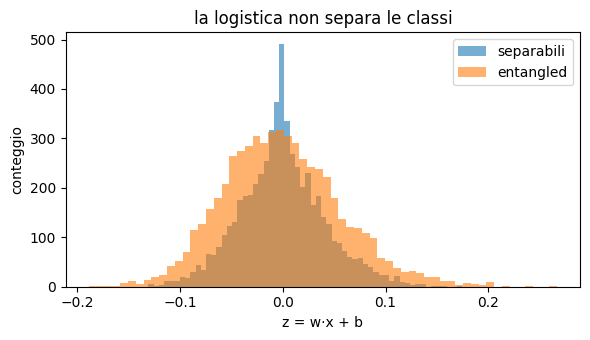

In [15]:
z_test = lr.decision_function(X_test_std)     # z = w . x + b per ogni stato del test (prima della sigmoide)

plt.figure(figsize=(6, 3.5))
plt.hist(z_test[y_test == 0], bins=60, alpha=0.6, label="separabili")
plt.hist(z_test[y_test == 1], bins=60, alpha=0.6, label="entangled")
plt.xlabel("z = w·x + b"); plt.ylabel("conteggio"); plt.title("la logistica non separa le classi")
plt.legend(); plt.tight_layout(); plt.show()

### 2.3 Perché un iperpiano non basta

Il motivo è geometrico. Gli stati separabili formano una regione **convessa** dello spazio delle feature, con al centro lo
stato di puro rumore (tutte le feature a 0); gli stati entangled la circondano **da ogni lato**. Un iperpiano può staccare
una sola "calotta" di entangled, quelli dalla sua parte; tutti gli altri finiscono insieme ai separabili. Con stati
distribuiti in ogni direzione il risultato è il caso, qualunque sia l'iperpiano.

Serve quindi un confine curvo, che avvolga la regione dei separabili. È quello che farà l'MLP del parte 3: ogni
neurone nascosto è un iperpiano, e la rete li combina in modo non lineare.

Un classificatore lineare sulle misure di Pauli ha un nome in fisica: **testimone di entanglement**, un osservabile che
vale $\ge 0$ su tutti gli stati separabili e che per costruzione rileva solo gli entangled da una parte dell'iperpiano.
Il risultato di questo notebook è la versione "imparata dai dati" di quel limite.

## Parte 3 — Il percettrone multistrato

La parte 2 ha mostrato che un solo iperpiano non basta. Qui si costruisce un **MLP**: ogni neurone nascosto calcola
la propria $z = \mathbf{w}\cdot\mathbf{x}+b$, la ReLU la rende non lineare, gli strati successivi combinano queste $z$. La rete è
scritta in PyTorch.

Percorso: (1) dati in training / validation / test e tensori, (2) definizione della rete, (3) procedura di addestramento,
(4) scelta dell'architettura, (5) regolarizzazione, (6) il modello scelto e le sue curve, (7) valutazione sul test e
confronto con la logistica.


In [16]:
torch.manual_seed(1)
np.random.seed(1)

df = pd.read_csv("dataset.csv")
X = df[q.NOMI_FEATURE].values.astype(np.float32)
y = df["entangled"].values.astype(np.float32)

### 3.1 Training, validation, test

Tre insiemi: il **training** (70 %) aggiorna i pesi; la **validation** (15 %) serve a decidere quando fermarsi (early
stopping); il **test** (15 %) si usa una sola volta alla fine per la stima onesta delle prestazioni. Lo scaler è stimato
sul solo training. I dati diventano tensori `float32`; l'etichetta ha forma `(n, 1)` per confrontarsi con l'unico logit
in uscita.

Il `DataLoader` mescola il training a ogni epoca e lo consegna a mini-batch di 128 esempi: batch piccoli danno aggiornamenti
più frequenti ma rumorosi, batch grandi un gradiente più stabile ma meno aggiornamenti per epoca; 128 è un compromesso
standard.

In [17]:
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.30, random_state=1, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.50, random_state=1, stratify=y_temp)

scaler = StandardScaler().fit(X_train)                       # media e std solo dal training
to_tensor = lambda a: torch.tensor(scaler.transform(a).astype(np.float32))
X_train_t, X_val_t, X_test_t = to_tensor(X_train), to_tensor(X_val), to_tensor(X_test)
y_train_t, y_val_t, y_test_t = (torch.tensor(a).reshape(-1, 1) for a in (y_train, y_val, y_test))

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=128, shuffle=True)
print(f"training {len(y_train)}   validation {len(y_val)}   test {len(y_test)}   batch per epoca: {len(train_loader)}")

training 26773   validation 5737   test 5738   batch per epoca: 210


### 3.2 La rete

15 ingressi (le feature), uno o più strati nascosti con ReLU, un'uscita. Ogni `nn.Linear(m, d)` calcola
$\mathbf{Z} = \mathbf{A}\,\mathbf{W}^{\mathsf T} + \mathbf{b}$ con $\mathbf{W}$ di dimensione $d\times m$ (una riga di pesi per
neurone); la ReLU, $\max(0, z)$, è l'attivazione degli strati nascosti e rende la rete non lineare. Il numero e la
larghezza degli strati nascosti sono un parametro della classe, così da poter confrontare più architetture.

L'uscita è **un solo logit** $z^{(out)}$, senza sigmoide: la probabilità $\hat y = \sigma(z^{(out)})$ la calcola la loss
`BCEWithLogitsLoss`, che vuole i logit per stabilità numerica. La classe predetta è $z^{(out)} > 0$, equivalente a
$\hat y > 0{,}5$.

La classe prevede anche un tasso di **dropout** (`nn.Dropout` dopo ogni ReLU), nullo per default: viene usato nella
sezione 3.5.


In [18]:
class RilevatoreEntanglement(nn.Module):
    def __init__(self, nascosti, dropout=0.0):   # nascosti: larghezze degli strati nascosti, es. (128, 64)
        super().__init__()
        strati = []
        n_in = 15
        for n_out in nascosti:
            strati += [nn.Linear(n_in, n_out), nn.ReLU()]   # z = a W^T + b, poi ReLU
            if dropout > 0:
                strati.append(nn.Dropout(dropout))          # attivo solo in model.train()
            n_in = n_out
        strati.append(nn.Linear(n_in, 1))         # uscita: un logit per stato, senza attivazione
        self.rete = nn.Sequential(*strati)

    def forward(self, x):
        return self.rete(x)

print(RilevatoreEntanglement((128, 64)))


RilevatoreEntanglement(
  (rete): Sequential(
    (0): Linear(in_features=15, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


### 3.3 Procedura di addestramento

Per ogni mini-batch: propagazione in avanti, loss, `loss.backward()` calcola il gradiente della loss rispetto a ogni peso
con la backpropagation, `optimizer.step()` aggiorna i pesi nella direzione opposta al gradiente. A fine epoca si misura
la loss sulla validation. **Early stopping**: si tiene la copia della rete con la validation loss più bassa e, se per
`pazienza` epoche consecutive la validation non migliora, l'addestramento si interrompe: continuare sarebbe solo
overfitting e tempo di calcolo sprecato. La procedura è racchiusa in una funzione, perché verrà usata più volte.

**Iperparametri.** La loss è la cross-entropy binaria sui logit (`BCEWithLogitsLoss`, la sigmoide è dentro), la stessa
funzione di costo della regressione logistica. L'ottimizzatore è Adam, discesa del gradiente con passo adattato peso per
peso, con learning rate $10^{-3}$ (il default): con $10^{-2}$ la loss oscilla, con $10^{-4}$ servono molte più epoche.
La pazienza è di 5 epoche: abbastanza da non fermarsi per un'oscillazione casuale della validation loss.

Il numero di epoche conta per il costo: ogni epoca dell'MLP scelto richiede circa $3 \cdot n \cdot 26\,881 \approx 2\cdot10^9$
moltiplicazioni (una per peso in avanti, circa due all'indietro), contro le $n \cdot 15$ dei modelli lineari.

In [19]:
def addestra(model, n_epoche_max=100, pazienza=5, lr=1e-3, weight_decay=0.0):
    loss_fn = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)   # weight_decay: penalità L2
    storia = {"train": [], "val": []}
    migliore = {"loss": np.inf, "epoca": 0, "pesi": None}

    for epoca in range(1, n_epoche_max + 1):
        model.train()
        loss_epoca = 0.0
        for X_b, y_b in train_loader:
            z = model(X_b)                  # forward
            loss = loss_fn(z, y_b)          # loss del batch
            optimizer.zero_grad()
            loss.backward()                 # backpropagation
            optimizer.step()                # aggiornamento dei pesi
            loss_epoca += loss.item()
        storia["train"].append(loss_epoca / len(train_loader))

        model.eval()
        with torch.no_grad():
            loss_val = loss_fn(model(X_val_t), y_val_t).item()
        storia["val"].append(loss_val)

        if loss_val < migliore["loss"]:     # nuova migliore: se ne conserva una copia
            migliore = {"loss": loss_val, "epoca": epoca,
                        "pesi": {k: v.clone() for k, v in model.state_dict().items()}}
        elif epoca - migliore["epoca"] >= pazienza:   # early stopping
            break

    model.load_state_dict(migliore["pesi"])
    return storia, migliore


def accuratezza(model, X_t, y):
    model.eval()
    with torch.no_grad():
        y_pred = (model(X_t).squeeze(1) > 0).numpy().astype(int)   # z > 0  <=>  probabilita' > 0.5
    return accuracy_score(y, y_pred)

### 3.4 Scelta dell'architettura

Si addestrano quattro reti di taglia crescente con la stessa procedura e si confronta l'**accuratezza sulla validation**
(non sul test, che deve restare intatto per la valutazione finale). Il criterio è prendere la rete più piccola che
raggiunge il massimo: una più grande costa di più e non impara nulla in più. Le reti addestrate e le loro curve vengono
conservate, così la rete scelta non va riaddestrata.

In [20]:
architetture = [(64, 32), (128, 64), (128, 128, 64), (256, 256, 128)]
prove = {}
for nascosti in architetture:
    torch.manual_seed(1)                                    # stessa inizializzazione per tutte
    model = RilevatoreEntanglement(nascosti)
    n_pesi = sum(p.numel() for p in model.parameters())
    storia, migliore = addestra(model)
    acc_val = accuratezza(model, X_val_t, y_val)
    prove[nascosti] = (model, storia, migliore)
    print(f"strati nascosti {str(nascosti):16s} parametri {n_pesi:6d}   epoca migliore {migliore['epoca']:2d} su {len(storia['val']):2d}   accuratezza validation {acc_val:.3f}")

strati nascosti (64, 32)         parametri   3137   epoca migliore 29 su 34   accuratezza validation 0.931


strati nascosti (128, 64)        parametri  10369   epoca migliore 37 su 42   accuratezza validation 0.943


strati nascosti (128, 128, 64)   parametri  26881   epoca migliore 16 su 21   accuratezza validation 0.954


strati nascosti (256, 256, 128)  parametri 102913   epoca migliore 10 su 15   accuratezza validation 0.954


L'accuratezza cresce con la taglia fino a tre strati (128, 128, 64) e poi si ferma: la rete più grande ha quattro volte i
parametri e dà lo stesso risultato. **Si sceglie (128, 128, 64).** Con 27 000 esempi e circa 27 000 parametri questa rete può memorizzare il training,
e infatti l'epoca migliore arriva presto: è l'early stopping a tenerla sotto controllo.

### 3.5 Regolarizzazione

Se la rete memorizza il training, oltre a fermarsi in tempo si può provare a **ridurre l'overfitting** durante l'addestramento.
Due tecniche:

- **dropout**: a ogni passo di addestramento una frazione $p$ dei neuroni nascosti viene spenta a caso, così la rete non può
  affidarsi a singoli neuroni e deve distribuire l'informazione; in fase di valutazione (`model.eval()`) tutti i neuroni sono
  attivi. In PyTorch è uno strato `nn.Dropout(p)` dopo ogni ReLU;
- **weight decay**: alla loss si aggiunge una penalità $\lambda \sum w^2$ che tiene piccoli i pesi (regolarizzazione L2); è il
  parametro `weight_decay` di Adam.

Il dropout e $\lambda$ sono iperparametri come gli altri: si prova qualche valore con la stessa architettura e si confronta
sulla validation la **loss migliore** (quella usata per l'early stopping) e l'accuratezza. La rete senza regolarizzazione è
quella già addestrata in 3.4.


In [21]:
varianti = {"nessuna":            dict(dropout=0.0, weight_decay=0.0),
            "dropout 0.1":        dict(dropout=0.1, weight_decay=0.0),
            "dropout 0.2":        dict(dropout=0.2, weight_decay=0.0),
            "dropout 0.3":        dict(dropout=0.3, weight_decay=0.0),
            "weight decay 1e-4":  dict(dropout=0.0, weight_decay=1e-4),
            "weight decay 1e-3":  dict(dropout=0.0, weight_decay=1e-3)}
prove_reg = {"nessuna": prove[(128, 128, 64)]}
for nome, par in varianti.items():
    if nome not in prove_reg:
        torch.manual_seed(1)
        model = RilevatoreEntanglement((128, 128, 64), dropout=par["dropout"])
        storia, migliore = addestra(model, weight_decay=par["weight_decay"])
        prove_reg[nome] = (model, storia, migliore)
    model, storia, migliore = prove_reg[nome]
    print(f"{nome:18s} loss validation {migliore['loss']:.4f}   epoca migliore {migliore['epoca']:2d} su {len(storia['val']):2d}   accuratezza validation {accuratezza(model, X_val_t, y_val):.3f}")


nessuna            loss validation 0.1185   epoca migliore 16 su 21   accuratezza validation 0.954


dropout 0.1        loss validation 0.1001   epoca migliore 28 su 33   accuratezza validation 0.956


dropout 0.2        loss validation 0.1008   epoca migliore 32 su 37   accuratezza validation 0.959


dropout 0.3        loss validation 0.1216   epoca migliore 32 su 37   accuratezza validation 0.950


weight decay 1e-4  loss validation 0.1197   epoca migliore 16 su 21   accuratezza validation 0.953


weight decay 1e-3  loss validation 0.1084   epoca migliore 25 su 30   accuratezza validation 0.954


Il weight decay abbassa di poco la loss di validazione e non l'accuratezza. Il dropout invece aiuta: con $p=0{,}1$ e $p=0{,}2$
la loss di validazione scende da 0,118 a 0,100 e l'accuratezza sale (i due valori sono equivalenti: 95,6 % e 95,9 % su
5 737 esempi differiscono di una ventina di stati); con $p=0{,}3$ la rete è troppo disturbata e peggiora. **Si adotta il
dropout 0,1**, il disturbo più piccolo che produce il guadagno: la rete finale è (128, 128, 64) con `nn.Dropout(0.1)` dopo
ogni ReLU, addestrata con Adam, early stopping e pazienza 5.

Costo della ricerca: le cinque reti in più richiedono circa 90 s su un core (158 epoche in tutto), il confronto fra
architetture circa 40 s; si pagano una volta sola. Il dropout costa poco per epoca (circa 0,5 s invece di 0,4) ma allunga la
convergenza (33 epoche invece di 21, circa 16 s invece di 9); non cambia l'inferenza, perché in `eval()` tutti i neuroni
sono attivi e i pesi sono gli stessi 26 881.

### 3.6 Il modello scelto

Si riprende la rete addestrata sopra e si confrontano le sue curve di apprendimento con quelle della rete senza dropout.


In [22]:
model, storia, migliore = prove_reg["dropout 0.1"]
for e in range(4, len(storia["val"]), 5):
    print(f"epoca {e+1:3d}   loss train {storia['train'][e]:.4f}   loss val {storia['val'][e]:.4f}")
print(f"\nfermato all'epoca {len(storia['val'])}; rete scelta: epoca {migliore['epoca']} con loss di validazione {migliore['loss']:.4f}")


epoca   5   loss train 0.1814   loss val 0.1713
epoca  10   loss train 0.1427   loss val 0.1315
epoca  15   loss train 0.1113   loss val 0.1172
epoca  20   loss train 0.0967   loss val 0.1056
epoca  25   loss train 0.0870   loss val 0.1101
epoca  30   loss train 0.0793   loss val 0.1018

fermato all'epoca 33; rete scelta: epoca 28 con loss di validazione 0.1001


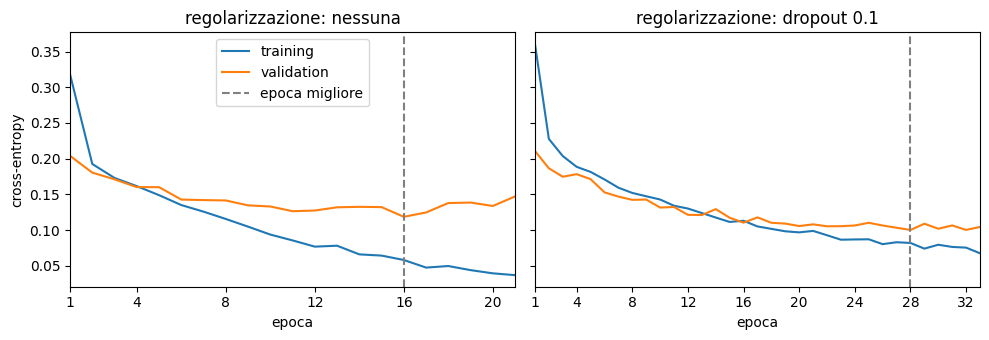

In [23]:
fig, assi = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, nome in zip(assi, ["nessuna", "dropout 0.1"]):
    _, st, mg = prove_reg[nome]
    n = len(st["train"])
    epoche = range(1, n + 1)
    ax.plot(epoche, st["train"], label="training")
    ax.plot(epoche, st["val"], label="validation")
    ax.axvline(mg["epoca"], color="gray", ls="--", label="epoca migliore")
    ax.set_xlim(1, n); ax.set_xticks([1] + list(range(4, n + 1, 4)))
    ax.set_xlabel("epoca"); ax.set_title(f"regolarizzazione: {nome}")
assi[0].set_ylabel("cross-entropy"); assi[0].legend()
plt.tight_layout(); plt.show()


A sinistra il quadro tipico dell'**overfitting**: la loss di training scende verso zero, perché la rete ha abbastanza
parametri per memorizzare gli esempi, mentre quella di validation tocca il minimo dopo una quindicina di epoche e poi
risale. A destra, con il dropout, la loss di training scende più lentamente (a ogni passo lavora una rete "mutilata"),
quella di validation arriva più in basso e il minimo si sposta più avanti. In entrambi i casi l'early stopping interrompe
l'addestramento cinque epoche dopo il minimo e restituisce la rete di quell'epoca.

### 3.7 Valutazione sul test

Si guardano accuratezza, matrice di confusione, precision e recall. In questo problema le due classi non hanno lo stesso
costo: **un falso positivo (dichiarare entangled uno stato separabile)** è l'errore più grave, perché si userebbe come
risorsa un entanglement che non c'è. Conta quindi la **precision** sulla classe 1.


In [24]:
model.eval()
with torch.no_grad():
    z_test = model(X_test_t).squeeze(1).numpy()
y_pred = (z_test > 0).astype(int)                 # z > 0  <=>  probabilita' > 0.5

print(f"accuratezza test MLP: {accuracy_score(y_test, y_pred):.4f}")
print(matrice_confusione(y_test, y_pred))
print()
print(classification_report(y_test, y_pred, target_names=["separabile", "entangled"], digits=3))

accuratezza test MLP: 0.9564
                   predetto: entangled  predetto: separabile
reale: entangled                  2742                   127
reale: separabile                  123                  2746

              precision    recall  f1-score   support

  separabile      0.956     0.957     0.956      2869
   entangled      0.957     0.956     0.956      2869

    accuracy                          0.956      5738
   macro avg      0.956     0.956     0.956      5738
weighted avg      0.956     0.956     0.956      5738



**Quanto ha dato il dropout.** Per verifica si misura sul test anche la rete senza regolarizzazione (la scelta, però, è
stata fatta sulla validation: il test qui serve solo a riportare il risultato, non a decidere).


In [25]:
for nome in ["nessuna", "dropout 0.1"]:
    m, st, mg = prove_reg[nome]
    print(f"regolarizzazione {nome:12s}  accuratezza test {accuratezza(m, X_test_t, y_test):.4f}   errori {int(round((1 - accuratezza(m, X_test_t, y_test)) * len(y_test))):3d} su {len(y_test)}")


regolarizzazione nessuna       accuratezza test 0.9507   errori 283 su 5738
regolarizzazione dropout 0.1   accuratezza test 0.9564   errori 250 su 5738


Il dropout vale mezzo punto: da 95,1 % a 95,6 %, cioè una trentina di errori in meno su 5 738. Il grosso del risultato
(dal 50 % dei lineari al 95 %) lo fa l'MLP con l'early stopping; la regolarizzazione è una rifinitura, coerente con quanto
visto sulla validation. Gli errori residui sono stati vicini al confine fra le classi, dove le medie delle misure delle due
classi differiscono di quantità minuscole.

Confronto con il modello lineare della parte 2, allenato sugli stessi dati.


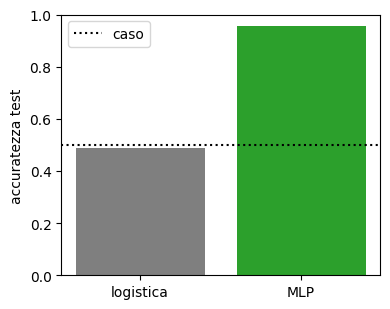

logistica 0.489   MLP 0.956


In [26]:
lr = LogisticRegression(max_iter=1000, random_state=1).fit(scaler.transform(X_train), y_train)
acc_lr = lr.score(scaler.transform(X_test), y_test)
acc_mlp = accuracy_score(y_test, y_pred)

plt.figure(figsize=(4, 3.2))
plt.bar(["logistica", "MLP"], [acc_lr, acc_mlp], color=["tab:gray", "tab:green"])
plt.axhline(0.5, color="k", ls=":", label="caso")
plt.ylim(0, 1); plt.ylabel("accuratezza test"); plt.legend(); plt.tight_layout(); plt.show()
print(f"logistica {acc_lr:.3f}   MLP {acc_mlp:.3f}")